In [1]:
# Step 2: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Step 3: Load cleaned dataset
df = pd.read_csv("data/cleaned_finance_data.csv")

In [3]:
# Step 4: Basic overview
print("Dataset shape:", df.shape)
print("Columns:", df.columns)
print(df.head())
print(df.describe(include="all"))

Dataset shape: (10000, 37)
Columns: Index(['client_id', 'persona_archetype', 'household_income_usd',
       'net_worth_usd', 'liquidity_30d_usd', 'cashflow_volatility_pct',
       'income_stream_count', 'primary_tax_bracket_pct',
       'jurisdiction_country', 'kyc_risk_flag', 'compliance_restrictions',
       'ethical_screens', 'product_blacklist', 'leverage_limit_x',
       'drawdown_tolerance_pct', 'target_volatility_pct', 'goal_stack',
       'time_horizon_primary_years', 'advice_style', 'explanation_depth',
       'preferred_metrics', 'channel_preference_ranked', 'nudges_opt_in',
       'notification_quiet_hours', 'trust_score_dynamic_1_100',
       'trust_decay_days', 'engagement_score_1_100', 'adherence_score_1_100',
       'consent_data_sources', 'data_freshness_days', 'advisor_relationship',
       'last_action_type', 'last_action_date', 'last_action_outcome',
       'model_version_current', 'safety_overrides', 'notes_agent_constraints'],
      dtype='str')
  client_id persona

In [4]:
# Step 5: Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
client_id                     0
persona_archetype             0
household_income_usd          0
net_worth_usd                 0
liquidity_30d_usd             0
cashflow_volatility_pct       0
income_stream_count           0
primary_tax_bracket_pct       0
jurisdiction_country          0
kyc_risk_flag                 0
compliance_restrictions       0
ethical_screens               0
product_blacklist             0
leverage_limit_x              0
drawdown_tolerance_pct        0
target_volatility_pct         0
goal_stack                    0
time_horizon_primary_years    0
advice_style                  0
explanation_depth             0
preferred_metrics             0
channel_preference_ranked     0
nudges_opt_in                 0
notification_quiet_hours      0
trust_score_dynamic_1_100     0
trust_decay_days              0
engagement_score_1_100        0
adherence_score_1_100         0
consent_data_sources          0
data_freshness_days           0
advisor_relat

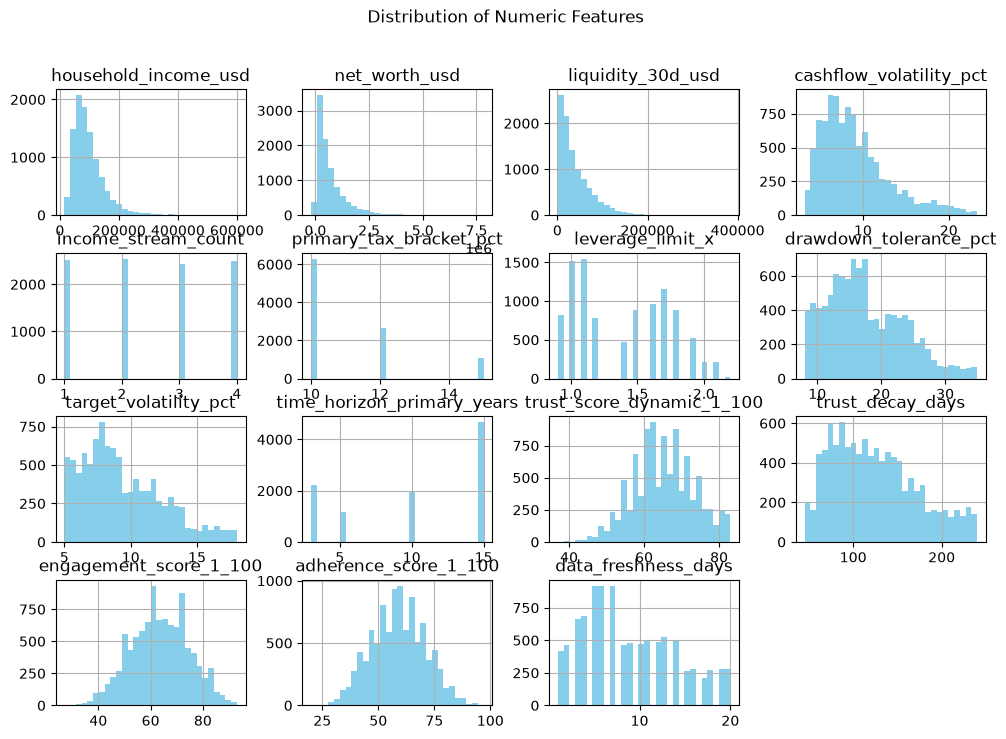

In [5]:
# Step 6: Distribution of numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols].hist(figsize=(12,8), bins=30, color="skyblue")
plt.suptitle("Distribution of Numeric Features")
plt.show()

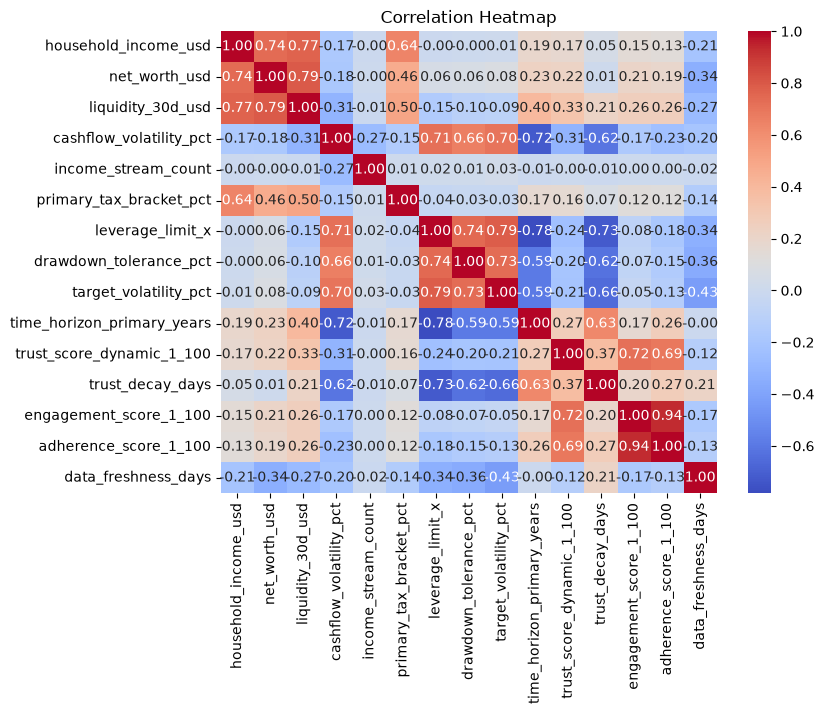

In [6]:
# Step 7: Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

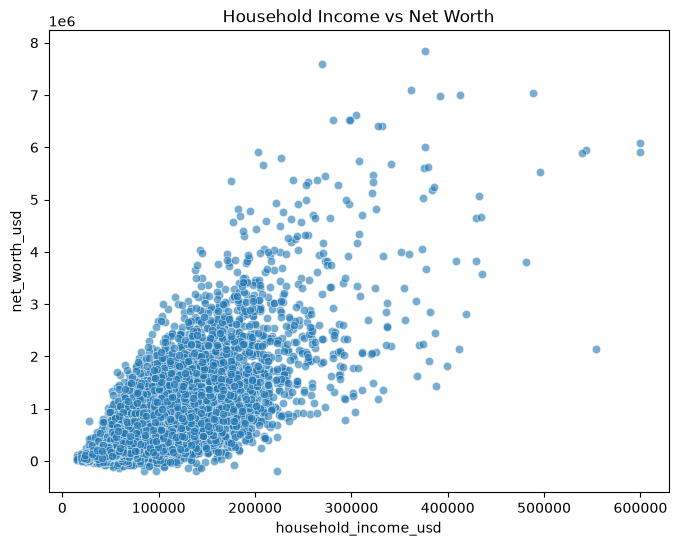

In [9]:
# Step 8: Relationship analysis (example: household_income_usd vs net_worth_usd)
if "household_income_usd" in df.columns and "net_worth_usd" in df.columns:
    plt.figure(figsize=(8,6))
    sns.scatterplot(x="household_income_usd", y="net_worth_usd", data=df, alpha=0.6)
    plt.title("Household Income vs Net Worth")
    plt.show()
else:
    print("⚠️ Columns household_income_usd and net_worth_usd not found.")

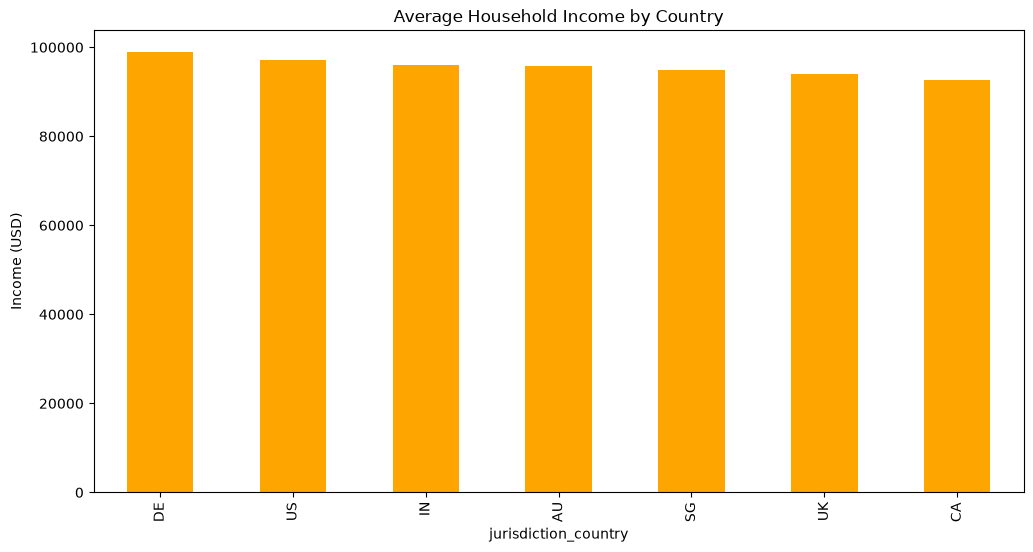

In [10]:
# Step 9: Grouping by categorical column (example: jurisdiction_country)
if "jurisdiction_country" in df.columns:
    country_income = df.groupby("jurisdiction_country")["household_income_usd"].mean().sort_values(ascending=False)
    plt.figure(figsize=(12,6))
    country_income.plot(kind="bar", color="orange")
    plt.title("Average Household Income by Country")
    plt.ylabel("Income (USD)")
    plt.show()
else:
    print("⚠️ Column jurisdiction_country not found.")

In [11]:
# Step 10: Save summary stats
summary = df.describe(include="all")
summary.to_csv("data/analysis_summary.csv")

print("✅ Data analysis complete. Summary saved as analysis_summary.csv")

✅ Data analysis complete. Summary saved as analysis_summary.csv
